# HSA_Cam_B_013.py
This file uses the LHHW_Model of kinetics and KLD to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_004.py is the model. This uses homoscedastic noise and exponential priors.

Analysis from the related python script.

### Plan:
* load the data
* generate the plots
* check the reduction in KLD
* check the reduction in HDI
* check the parameter uncertainties
* check the exploration pattern

### Results:
* Leave out the first 4 experiments completely

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import torch
import arviz as az
import ICIW_Plots

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_B_016_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_007_pyro import kinetics_model, sample_prior

In [3]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = calculate_partial_pressures(p, c2h, f, c2i)
    res = predict(
        idata,
        T,
        p_i,
        num_samples=1000,
        key=key,
    )
    HDI = torch.quantile(res, 0.975) - torch.quantile(res, 0.025)
    return -HDI

In [4]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range for evaluation
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(T, p, c2h, f, c2i, rel_noise_std=0.0)

    return true_rates.cpu().numpy()


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    # Add condition text
    # condition_text = (
    #     f"Conditions:\n"
    #     f"p = {proposal[1]:.1f} bar\n"
    #     f"CO2/H2 = {proposal[2]:.2f}\n"
    #     f"Feed ratio = {proposal[3]:.1f}\n"
    #     f"CO2/Inert = {proposal[4]:.2f}"
    # )
    # ax.text(
    #     0.02,
    #     0.8,
    #     condition_text,
    #     transform=ax.transAxes,
    #     fontsize=9,
    #     verticalalignment="top",
    #     bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    # )

    # Second y-axis for HDI width
    # ax2 = ax.twinx()
    # hdi_width = np.percentile(posterior_preds, 97.5, axis=1) - np.percentile(
    #     posterior_preds, 2.5, axis=1
    # )
    # ax2.plot(T_range, hdi_width, color="orange", alpha=0.7, linewidth=2)
    # ax2.set_ylabel("HDI Width", color="orange")
    # ax2.tick_params(axis="y", labelcolor="orange")

    # plt.title("Posterior Predictions vs True Model")
    # plt.tight_layout()
    return fig, ax

In [5]:
exp_run_name = "asymptotic-strike"  # VI
# exp_run_name = "clumpy-ball" # MCMC
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [6]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [8]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.prior = sample_prior(4000).prior
    else:
        idata.prior = idatas[i - 1].posterior

In [9]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [10]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

### Display the results:

In [11]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), IntSlider(value=0, description='Pr…

### Generate the exploration pattern

C:\Users\hanne\AppData\Local\Temp\ipykernel_4968\2035428282.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



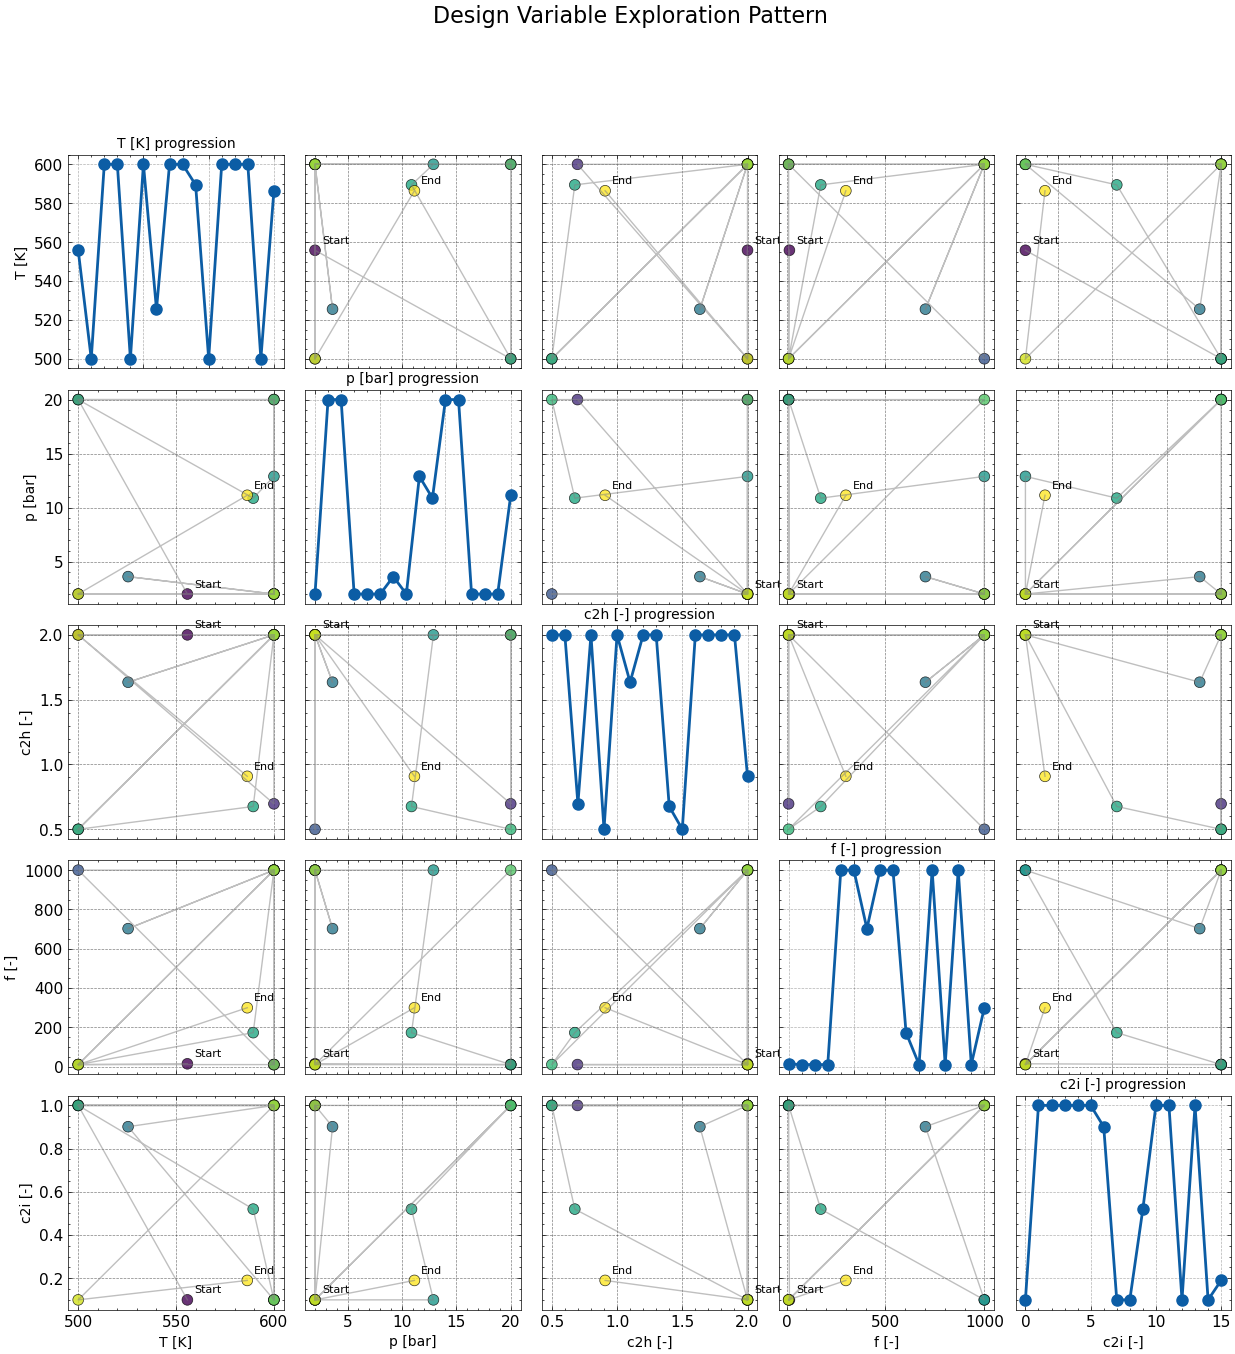

In [12]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = ["T [K]", "p [bar]", "c2h [-]", "f [-]", "c2i [-]"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Quantify the information gain

In [13]:
import xarray

info_gains = []
for i in range(1, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i - 1],
        key_new="posterior",
        key_old="posterior" if i > 1 else "prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[0.91744823 1.16072575 0.11106711 0.04648719 0.40834603 0.98955569
 0.73430781 0.47932959 1.1453468 ]
5.992614194925052
[2.06594127 2.75573101 0.009857   0.05069845 1.7432845  1.07784503
 1.24053114 0.15317328 2.04070055]
11.137762234090669
[0.19713583 0.08014639 0.07135565 0.01030219 0.11273745 0.00853853
 0.06539273 0.06965807 0.14509101]
0.7603578489817938
[0.2824162  0.17553205 0.04361361 0.03174312 0.34711005 0.0113077
 0.40697595 0.08589591 0.40808969]
1.7926842737358684
[0.05106327 0.01396803 0.01339742 0.11301565 0.00895897 0.0114374
 0.01720679 0.00926263 0.44005302]
0.6783631893066846
[0.64981136 0.1034456  0.08382398 0.05838652 0.41608715 0.02118275
 0.37646405 0.1328153  1.48529116]
3.3273078691876568
[0.16944515 0.02857456 0.02085941 0.01541798 0.00485775 0.00590705
 0.07155771 0.0411531  0.07020909]
0.42798180440458183
[0.01268537 0.0345929  0.05852049 0.01640223 0.01303764 0.0088774
 0.0240085  0.03970574 0.07005064]
0.2778809093767365
[0.01912984 0.00589861 0.04266704 0

In [14]:
expected_KLDs = [
    trial["next_proposal"]["expected_KLD"] for trial in exp_summary["trials"]
]

Text(0, 0.5, 'info gain as per KL divergence')

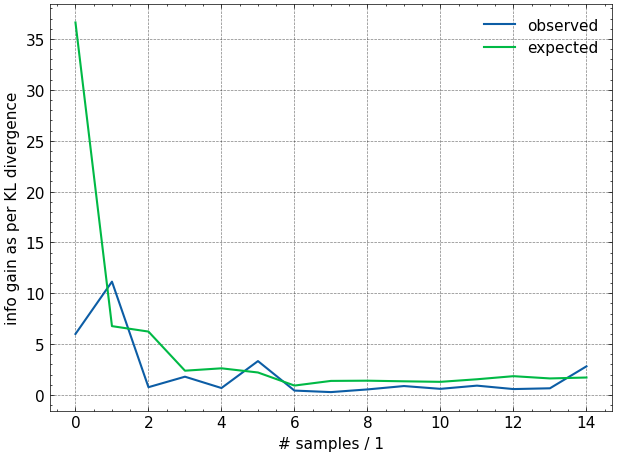

In [15]:
plt.plot(np.arange(len(kldses)), kldses, label="observed")
plt.plot(np.arange(len(kldses)), expected_KLDs[:-1], label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

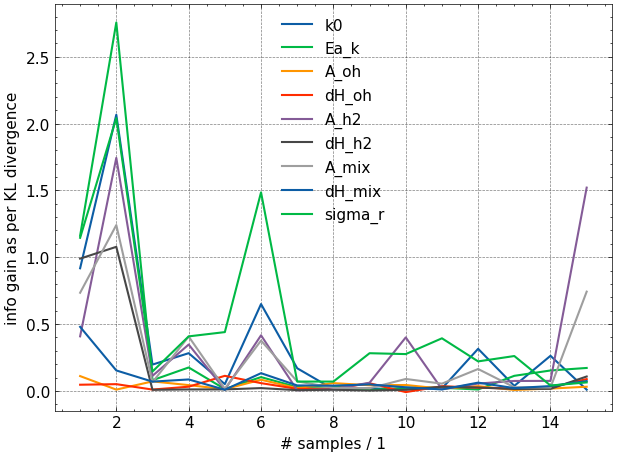

In [16]:
plt.plot(
    np.arange(len(kldses)) + 1,
    info_gains,
    label=[
        "k0",
        "Ea_k",
        "A_oh",
        "dH_oh",
        "A_h2",
        "dH_h2",
        "A_mix",
        "dH_mix",
        "sigma_r",
    ],
)
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [17]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h2', 'A_mix', 'dH_mix', 'sigma_r']


interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

In [18]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(i, key):
    az.plot_dist_comparison(idatas[i], var_names=[key], figsize=(4, 4))

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), Dropdown(description='Parameter:',…

In [19]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        kind=["scatter", "kde"],
        point_estimate="median",
        marginals=True,
    ).flatten()
    axs[2].set(
        xlim=(8e-5, 1e-3),
        # xscale="log",
        ylim=(30e3, 130e3),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=15), Output()), _dom_classes=('widget-i…

In [20]:
az.summary(idatas[-1], round_to=5)

arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k0[0],0.00034,0.00002,0.00031,0.00037,0.00000,0.00000,3815.13504,3809.02288,NaN
Ea_k[0],74313.89062,2937.52637,68758.73438,79851.18750,50.14432,34.78165,3431.26379,3882.10497,NaN
A_oh[0],0.97406,1.28766,0.01274,2.84353,0.02086,0.08277,3426.82570,3709.82136,NaN
dH_oh[0],9535.41406,12013.55469,237.06960,27424.77344,191.09011,582.73255,3763.95697,3515.33533,NaN
A_h2[0],0.36946,0.04884,0.28219,0.46256,0.00076,0.00059,4151.34620,3578.74900,NaN
dH_h2[0],-10184.83398,1835.41089,-13626.49414,-6705.60840,31.15599,21.26655,3468.66903,3921.53049,NaN
A_mix[0],0.92494,0.07087,0.79177,1.05181,0.00112,0.00081,4075.62550,4088.82022,NaN
dH_mix[0],-10638.69824,2393.84326,-14974.75586,-5965.85352,41.34741,27.89782,3340.70998,3977.03589,NaN
sigma_r[0],0.06509,0.01175,0.04431,0.08673,0.00019,0.00014,3683.98107,3553.07748,NaN


In [21]:
print(idatas[-1].posterior)

<xarray.Dataset> Size: 176kB
Dimensions:        (chain: 1, draw: 4000, k0_dim_0: 1, Ea_k_dim_0: 1,
                    A_oh_dim_0: 1, dH_oh_dim_0: 1, A_h2_dim_0: 1,
                    dH_h2_dim_0: 1, A_mix_dim_0: 1, dH_mix_dim_0: 1,
                    sigma_r_dim_0: 1)
Coordinates:
  * chain          (chain) int64 8B 0
  * draw           (draw) int64 32kB 0 1 2 3 4 5 ... 3995 3996 3997 3998 3999
  * k0_dim_0       (k0_dim_0) int64 8B 0
  * Ea_k_dim_0     (Ea_k_dim_0) int64 8B 0
  * A_oh_dim_0     (A_oh_dim_0) int64 8B 0
  * dH_oh_dim_0    (dH_oh_dim_0) int64 8B 0
  * A_h2_dim_0     (A_h2_dim_0) int64 8B 0
  * dH_h2_dim_0    (dH_h2_dim_0) int64 8B 0
  * A_mix_dim_0    (A_mix_dim_0) int64 8B 0
  * dH_mix_dim_0   (dH_mix_dim_0) int64 8B 0
  * sigma_r_dim_0  (sigma_r_dim_0) int64 8B 0
Data variables:
    k0             (chain, draw, k0_dim_0) float32 16kB 0.0003517 ... 0.0003268
    Ea_k           (chain, draw, Ea_k_dim_0) float32 16kB 7.336e+04 ... 7.502...
    A_oh           (chain, dr

In [22]:
info_gains[0]
temp_klds = xarray.DataArray(
    dims=["hyp_sample", "parameter"],
    coords={
        "hyp_sample": np.arange(15),
        "parameter": [
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    },
    data=info_gains,
)
display(temp_klds.sel(parameter="sigma_r").mean(axis=0))

<xarray.DataArray ()> Size: 8B
array(0.48951588)
Coordinates:
    parameter  <U7 28B 'sigma_r'